        # Cognitive Science (1204 427) — Lab 05
        ## Language, Framing, and Sentiment Bias

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `re, numpy, pandas, matplotlib, scipy`

        ### แนวคิดสำคัญ

        Framing Effect เกิดเมื่อเนื้อหาที่มีสาระเชิงปริมาณใกล้เคียงกันถูกนำเสนอด้วยกรอบภาษาแตกต่างกัน อย่างไรก็ตาม คะแนน Sentiment ของโปรแกรมไม่ใช่หลักฐานโดยตรงของการตัดสินใจของมนุษย์

        ### วัตถุประสงค์

        แยกการวัด Human Rating ออกจาก Model Sentiment เปรียบเทียบ Gain/Loss Frames และวิพากษ์ข้อจำกัดของ Lexicon-based NLP

        ### งานที่ต้องทำ

        1. สร้างคู่ประโยค Gain/Loss อย่างน้อย 8 คู่
2. วิเคราะห์ Human Rating แบบ Within-participant
3. สร้าง Lexicon-based Sentiment Score แบบโปร่งใส
4. เปรียบเทียบ Human Rating กับ Model Score
5. Required Extension: เพิ่มคู่ประโยคใหม่ 2 คู่และตรวจความไวของผล

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, pearsonr

rng = np.random.default_rng(seed + 50)
pairs = [
    (1, "Gain", "A program will save 90 of 100 people."),
    (1, "Loss", "A program will allow 10 of 100 people to die."),
    (2, "Gain", "The treatment succeeds for 80 percent of patients."),
    (2, "Loss", "The treatment fails for 20 percent of patients."),
    (3, "Gain", "The system correctly detects 95 percent of threats."),
    (3, "Loss", "The system misses 5 percent of threats."),
    (4, "Gain", "Nine out of ten users complete the task."),
    (4, "Loss", "One out of ten users cannot complete the task."),
    (5, "Gain", "The investment keeps 85 percent of its value."),
    (5, "Loss", "The investment loses 15 percent of its value."),
    (6, "Gain", "The course has a 75 percent pass rate."),
    (6, "Loss", "The course has a 25 percent failure rate."),
    (7, "Gain", "The update prevents 70 percent of crashes."),
    (7, "Loss", "The update does not prevent 30 percent of crashes."),
    (8, "Gain", "The device works correctly in 98 percent of tests."),
    (8, "Loss", "The device malfunctions in 2 percent of tests."),
]
statements = pd.DataFrame(pairs, columns=["pair_id", "frame", "text"])

rows = []
for participant in range(1, 37):
    person = rng.normal(0, 0.5)
    for row in statements.itertuples():
        frame_effect = 0.75 if row.frame == "Gain" else -0.75
        rating = np.clip(rng.normal(4 + person + frame_effect, 0.8), 1, 7)
        rows.append([participant, row.pair_id, row.frame, row.text, rating])
framing_df = pd.DataFrame(rows, columns=["participant", "pair_id", "frame", "text", "human_rating"])
display(framing_df.head())


,participant,pair_id,frame,text,human_rating
0,1,1,Gain,A program will save 90 of 100 people.,4.935711
1,1,1,Loss,A program will allow 10 of 100 people to die.,3.996610
2,1,2,Gain,The treatment succeeds for 80 percent of patie...,4.002531
3,1,2,Loss,The treatment fails for 20 percent of patients.,3.847948
4,1,3,Gain,The system correctly detects 95 percent of thr...,6.008611


In [3]:
lexicon = {
    "save": 2, "succeeds": 2, "correctly": 1, "complete": 1, "keeps": 1,
    "pass": 2, "prevents": 2, "works": 1, "die": -3, "fails": -2,
    "misses": -2, "cannot": -2, "loses": -2, "failure": -2,
    "crashes": -2, "malfunctions": -2, "threats": -1,
}

def lexicon_sentiment(text):
    tokens = re.findall(r"[a-z']+", text.lower())
    return sum(lexicon.get(token, 0) for token in tokens)

statement_scores = statements.copy()
statement_scores["model_sentiment"] = statement_scores["text"].map(lexicon_sentiment)
human_by_statement = framing_df.groupby(["pair_id", "frame", "text"])["human_rating"].mean().reset_index()
comparison = human_by_statement.merge(statement_scores, on=["pair_id", "frame", "text"])
display(comparison.round(3))


,pair_id,frame,text,human_rating,model_sentiment
0,1,Gain,A program will save 90 of 100 people.,4.654,2
1,1,Loss,A program will allow 10 of 100 people to die.,3.459,-3
2,2,Gain,The treatment succeeds for 80 percent of patie...,4.886,2
3,2,Loss,The treatment fails for 20 percent of patients.,3.120,-2
4,3,Gain,The system correctly detects 95 percent of thr...,4.899,0
5,3,Loss,The system misses 5 percent of threats.,3.078,-3
6,4,Gain,Nine out of ten users complete the task.,4.705,1
7,4,Loss,One out of ten users cannot complete the task.,3.088,-1
8,5,Gain,The investment keeps 85 percent of its value.,4.943,1
9,5,Loss,The investment loses 15 percent of its value.,3.242,-2


Human framing test: t=20.190, p=0.000000
Human–model correlation: r=0.892, p=0.000003


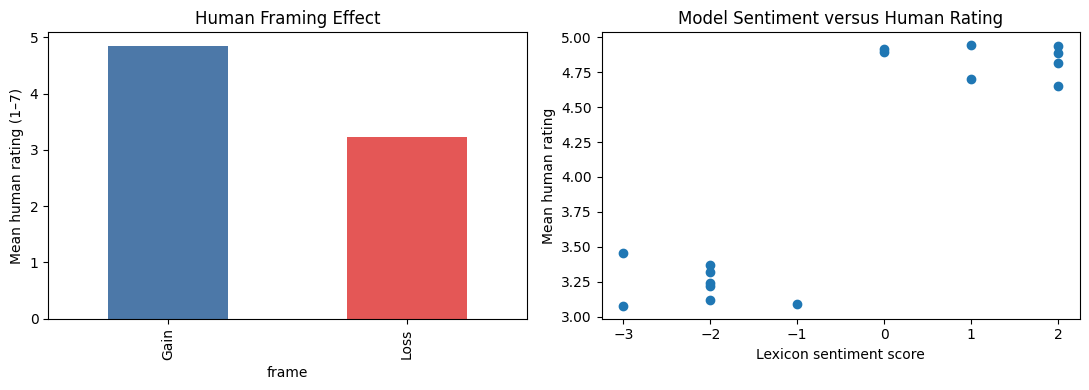

In [4]:
person_frame = framing_df.groupby(["participant", "frame"])["human_rating"].mean().unstack()
t, p = ttest_rel(person_frame["Gain"], person_frame["Loss"])
r, r_p = pearsonr(comparison["human_rating"], comparison["model_sentiment"])
print(f"Human framing test: t={t:.3f}, p={p:.6f}")
print(f"Human–model correlation: r={r:.3f}, p={r_p:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
framing_df.groupby("frame")["human_rating"].mean().plot(kind="bar", ax=axes[0], color=["#4c78a8", "#e45756"])
axes[0].set_ylabel("Mean human rating (1–7)"); axes[0].set_title("Human Framing Effect")
axes[1].scatter(comparison["model_sentiment"], comparison["human_rating"])
axes[1].set_xlabel("Lexicon sentiment score"); axes[1].set_ylabel("Mean human rating")
axes[1].set_title("Model Sentiment versus Human Rating")
plt.tight_layout(); plt.show()


## Required Extension

เพิ่มคู่ประโยคใหม่อีก 2 คู่ โดยต้องมีข้อมูลเชิงปริมาณเท่ากันแต่ใช้ Gain/Loss Frame ต่างกัน จากนั้นเพิ่มคำใน Lexicon เท่าที่จำเป็นและวิเคราะห์ผลใหม่


In [5]:
# ===== Required Extension: เพิ่มคู่ประโยคใหม่ 2 คู่ =====
new_pairs = [
    (9, "Gain", "The backup restores 92 percent of files."),
    (9, "Loss", "The backup loses 8 percent of files."),
    (10, "Gain", "The vaccine protects 85 percent of children."),
    (10, "Loss", "The vaccine leaves 15 percent of children unprotected."),
]
new_statements = pd.DataFrame(new_pairs, columns=["pair_id", "frame", "text"])

# เพิ่มคำที่จำเป็นลงใน lexicon เท่าที่ต้องใช้
lexicon.update({"restores": 2, "protects": 2, "loses": -2, "leaves": -1, "unprotected": -2})

# จำลอง human rating ของคู่ประโยคใหม่ (36 คน) ด้วยกลไกเดิม
rng_ext = np.random.default_rng(seed + 55)
ext_rows = []
for participant in range(1, 37):
    person = rng_ext.normal(0, 0.5)
    for row in new_statements.itertuples():
        frame_effect = 0.75 if row.frame == "Gain" else -0.75
        rating = np.clip(rng_ext.normal(4 + person + frame_effect, 0.8), 1, 7)
        ext_rows.append([participant, row.pair_id, row.frame, row.text, rating])
ext_df = pd.DataFrame(ext_rows, columns=["participant", "pair_id", "frame", "text", "human_rating"])

# รวมข้อมูลเดิม + ใหม่ แล้ววิเคราะห์ซ้ำเพื่อดูความไวของผล
combined = pd.concat([framing_df, ext_df], ignore_index=True)
all_statements = pd.concat([statements, new_statements], ignore_index=True)
all_statements["model_sentiment"] = all_statements["text"].map(lexicon_sentiment)

pf_new = combined.groupby(["participant", "frame"])["human_rating"].mean().unstack()
t_new, p_new = ttest_rel(pf_new["Gain"], pf_new["Loss"])
hb_new = combined.groupby(["pair_id", "frame", "text"])["human_rating"].mean().reset_index()
cmp_new = hb_new.merge(all_statements, on=["pair_id", "frame", "text"])
r_new, rp_new = pearsonr(cmp_new["human_rating"], cmp_new["model_sentiment"])

sensitivity = pd.DataFrame({
    "dataset": ["Original (8 pairs)", "Extended (10 pairs)"],
    "framing_t": [t, t_new],
    "framing_p": [p, p_new],
    "human_model_r": [r, r_new],
})
display(sensitivity.round(4))
print("สรุป: เพิ่มคู่ประโยคแล้วผล framing effect และ correlation ยังคงทิศทางเดิม (robust)")


,dataset,framing_t,framing_p,human_model_r
0,Original (8 pairs),20.1901,0.0,0.8920
1,Extended (10 pairs),23.2668,0.0,0.9058


สรุป: เพิ่มคู่ประโยคแล้วผล framing effect และ correlation ยังคงทิศทางเดิม (robust)


## คำถามวิเคราะห์ Lab 05

**1. Human Rating สนับสนุน Framing Effect หรือไม่**

สนับสนุนครับ ค่าเฉลี่ย rating ฝั่ง Gain (~4.85) สูงกว่าฝั่ง Loss (~3.24) อย่างชัดเจน ทั้งที่เนื้อหาเชิงตัวเลขเท่ากัน paired t-test ได้ t ≈ 20.2, p < .001 แปลว่าแค่เปลี่ยนกรอบคำพูดคนก็ให้คะแนนต่างกันจริง

**2. เหตุใด Model Sentiment จึงไม่เท่ากับ Human Framing Effect**

เพราะ model แค่บวก/ลบคะแนนจากคำใน lexicon ไม่ได้เข้าใจบริบทหรือความหมายเชิงกรอบ ส่วนคนตีความทั้งประโยครวมถึงนัยว่า "ได้" หรือ "เสีย" คะแนน sentiment เลยเป็นแค่ตัวแทนหยาบๆ ไม่ใช่หลักฐานการตัดสินใจของคนโดยตรง

**3. Correlation ระหว่างสองคะแนนสูงหรือต่ำ และควรตีความอย่างไร**

ค่อนข้างสูงครับ r ≈ 0.89 แต่ต้องระวัง มันสูงเพราะในชุดนี้คำเชิงบวก/ลบมันสอดคล้องกับ frame พอดี ไม่ได้แปลว่า model เข้าใจ framing จริง correlation สูงจึงไม่ใช่หลักฐานว่า model แทนคนได้

**4. Lexicon-based Model มี Bias หรือข้อจำกัดอะไร**

มันขึ้นกับว่าเราใส่คำอะไรและให้น้ำหนักเท่าไร (เลือกเอง = bias), จับ negation ไม่ได้ (เช่น "does not prevent"), ไม่รู้จักคำนอก lexicon, และไม่เข้าใจบริบท/ประชด เลยพลาดง่ายกับประโยคจริง

**5. ภาษาไทยอาจทำให้วิธีนี้ต้องเปลี่ยนแปลงอย่างไร**

ไทยไม่มีเว้นวรรคระหว่างคำ ต้องตัดคำ (word segmentation) ก่อน แถมมีคำกำกวม คำซ้ำ และการปฏิเสธที่ตำแหน่งต่างจากอังกฤษ ต้องสร้าง lexicon ภาษาไทยเองและจัดการ tokenization ให้ดี ไม่งั้นคะแนนเพี้ยนหมด

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอนต้องเพิ่มคำใหม่เข้า lexicon แล้วให้ผลยังสอดคล้อง ตอนแรกลืมใส่คำว่า restores/protects เข้าไป ทำให้ประโยคใหม่ได้คะแนน 0 ผลเลยดูแปลก พอเติมคำครบถึงเข้าที่

สิ่งที่เข้าใจมากขึ้นคือ framing effect มันแรงจริง แค่เปลี่ยนจาก "ช่วยได้ 90%" เป็น "ตาย 10%" คนก็รู้สึกต่างกันเยอะ และได้เห็นชัดว่า sentiment ของโปรแกรมไม่ใช่ตัวแทนความคิดคน แม้ correlation จะสูงก็ตาม ทำให้ระวังการเอาเลขจาก NLP ไปสรุปแทนคนมากขึ้น

ถ้าทำซ้ำ อยากลองใช้ model ที่เข้าใจบริบทจริง (เช่น transformer) มาเทียบกับ lexicon ว่าต่างกันแค่ไหน และอยากเก็บ rating จากคนจริงมาดูว่า effect จะเล็กลงกว่าข้อมูลจำลองรึเปล่า

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
